# 5. Join your data by edge_id

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Khoshkhah/duckOSM/blob/main/docs/notebooks/05_join_by_edge_id.ipynb) [Download the notebook](https://github.com/Khoshkhah/duckOSM/raw/main/docs/notebooks/05_join_by_edge_id.ipynb)

You join traffic counts to the edges by `edge_id` and color the map by the counts. The counts in this notebook are made up.

`edge_id` is a `BIGINT` content hash of the OSM way and the two ends of the edge. It is the same after a rebuild, so data joined on it stays correct.

In [1]:
# Install duckOSM when it is not installed (for example in Colab). It takes approximately 1 minute.
try:
    import duckosm
except ImportError:
    %pip install -q "duckosm[widget]" roadstyle
    import duckosm
print("duckosm", duckosm.__version__)

duckosm 0.8.0


In [2]:
area = duckosm.get("Monaco", out="data")      # the OSM file of Monaco and its boundary
db = duckosm.build(pbf=area.pbf, boundary=area.boundary, modes=["driving"],
                   output="data/monaco.duckdb")    # the driving network in one DuckDB file
db

PosixPath('data/monaco.duckdb')

## Make the counts

One count for each direction of the main roads, as an external file can give them. Keep the column type `int64`: a float or a text column loses the hash.

In [3]:
import numpy as np

main = duckosm.edges(db, where="highway IN ('primary', 'secondary', 'tertiary')")    # the main roads
base = main.highway.map({"primary": 900, "secondary": 500, "tertiary": 250})        # vehicles per hour, by class
rng = np.random.default_rng(1)
counts = main[["edge_id"]].assign(vehicles_per_hour=(base * rng.uniform(0.5, 1.5, len(main))).round().astype(int))
print(counts.dtypes.to_dict())
counts.head()

{'edge_id': dtype('int64'), 'vehicles_per_hour': dtype('int64')}


,edge_id,vehicles_per_hour
0,24138324208710596,506
1,25722618171067748,1305
2,27407470953641313,322
3,30114210838040685,724
4,54233354089271892,406


## Join in DuckDB

DuckDB reads the pandas table `counts` by its name.

In [4]:
import duckdb

con = duckdb.connect(str(db), read_only=True)
joined = con.sql("""SELECT e.edge_id, e.name, e.highway, c.vehicles_per_hour
                     FROM driving.edges e JOIN counts c USING (edge_id)""").df()    # the counts on the edges
print(len(counts), "counts,", len(joined), "joined")
joined.sort_values("vehicles_per_hour", ascending=False).head()

1013 counts, 1013 joined


,edge_id,name,highway,vehicles_per_hour
812,7273866584570309072,NaN,primary,1324
233,2112309560693974313,Boulevard du Larvotto,primary,1312
234,2113142360788194299,NaN,primary,1309
933,8528436742631886103,Tunnel Pasteur,primary,1308
221,1943370964926618174,Tunnel Albert II,primary,1307


## Color the map by the counts

Edges without a count are gray. Run the cell to see the live map: you can zoom, and click a road to see its columns. This page shows a picture of the map.

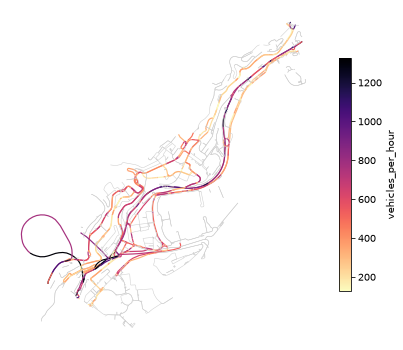

In [5]:
gdf = duckosm.edges(db).merge(counts, on="edge_id", how="left")    # the edges with their counts
duckosm.show_edges(gdf, color_by="vehicles_per_hour", cmap="magma_r")  # a map, colored by the count

## The ids stay after a rebuild

Build Monaco again into a new file. The same counts join to the same edges, with no change.

In [6]:
again = duckosm.build(pbf=area.pbf, boundary=area.boundary, modes=["driving"], output="data/monaco_again.duckdb")
n = counts.edge_id.isin(duckosm.edges(again).edge_id).sum()    # the counts whose edge_id is in the new build
print(n, "of", len(counts), "counts join to the new build")
con.close()

1013 of 1013 counts join to the new build
